# Real data example: air quality in Athens

Each realization of the random set is the **convex hull of the daily measurements** of temperature and ozone at one monitoring station. The notebook draws a random sample of 300 station-days and shows its quantile sets $K_\alpha$ together with other diagnostic plots.

*Data:* stored in `/data/athens_data.csv`.

*Requires:* `numpy`, `matplotlib`, `pandas`, `scipy`, `cartopy`, `pycvxset` and a LaTeX installation (for figure labels).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from PolytopeRandomSet import PolytopeRandomSet
from utils import load_athens_hulls, set_plotting_style, save_figure

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)
SEED = 2026            # seed for the random number generator

TEMP_LABEL = "Temp (°C)"
OZONE_LABEL = r"Ozone ($\mu$g/m$^3$)"

### 1. Data
One realization is the convex hull of the measurements of one station on one day (station-days with fewer than 3 measurements are skipped). Only dates between 1 June and 1 September 2022 are used.

In [2]:
all_hulls = load_athens_hulls("Temp", "O3", date_from="2022-06-01", date_to="2022-09-01")

### 2. Random sample
300 station-days are drawn without replacement (fixed seed).

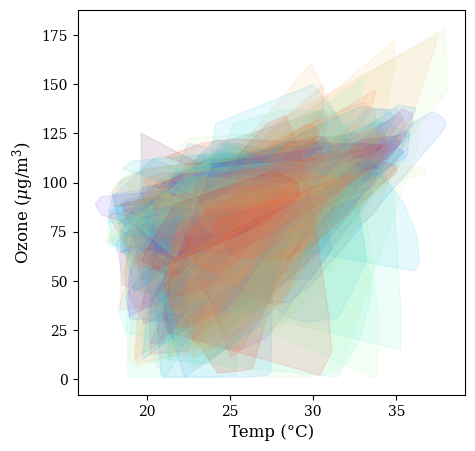

In [3]:
N = 300
rng = np.random.default_rng(SEED)
sample = rng.choice(all_hulls, N, replace=False)

fig, ax = plt.subplots(figsize=(5, 5))
cmap = plt.get_cmap("rainbow", N)
for i, stationday in enumerate(sample):
    stationday["hull_polytope"].plot2d(
        ax=ax, patch_args={"fc": cmap(i), "ec": cmap(i), "alpha": 0.1, "zorder": rng.integers(1, 10)})

ax.set_xlabel(TEMP_LABEL, size=12)
ax.set_ylabel(OZONE_LABEL, size=12)
if SAVE_FIGURES: save_figure(fig, "images/athens_data_hulls")
plt.show()

### 3. Quantile sets $K_\alpha$
Quantiles for 21 equally spaced levels $\alpha \in [0, 1]$, colored by $\alpha$.

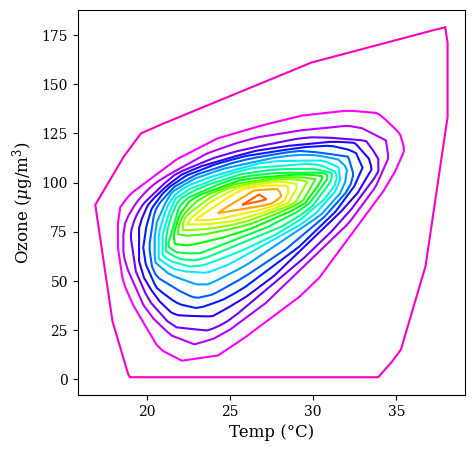

In [13]:
RS = PolytopeRandomSet([r["hull_polytope"] for r in sample])

ax = RS.plot_quantiles(np.linspace(0, 1, 21))
ax.figure.set_size_inches(5, 5)
ax.set_aspect("auto")
ax.set_xlabel(TEMP_LABEL, size=12)
ax.set_ylabel(OZONE_LABEL, size=12)
if SAVE_FIGURES: save_figure(ax.figure, "images/athens_data_quantiles")
plt.show()

### 4. Median set and bagplot

In [14]:
alpha_max, median_polytope = RS.median_set()
print(f"alpha_max: {alpha_max}")
print(f"Centroid of the median set: {median_polytope.interior_point('centroid')}")

alpha_max: 0.9223
Centroid of the median set: [26.68020962 91.42856349]


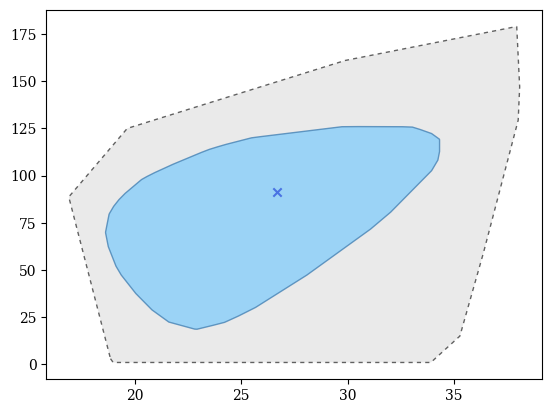

In [15]:
ax = RS.bagplot()
if SAVE_FIGURES: save_figure(ax.figure, "images/athens_data_bagplot", fig_size=(4, 4))
plt.show()

### 5. Pairplot

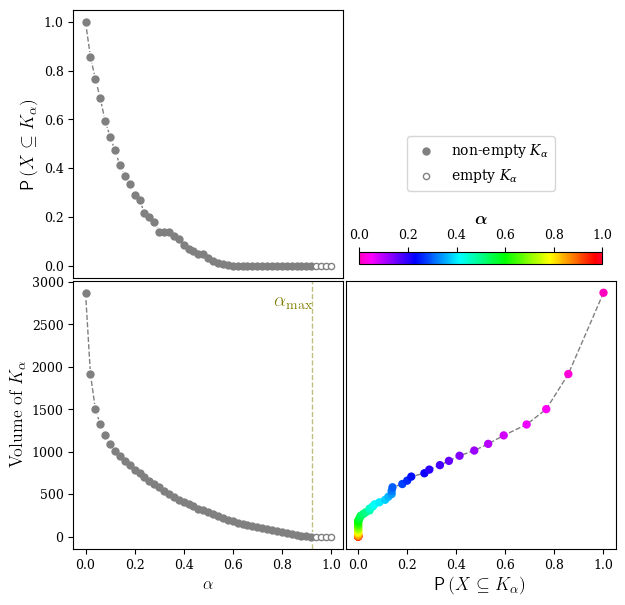

In [16]:
fig, ax = RS.pairplot()
plt.show()

### 6. Symmetry plot

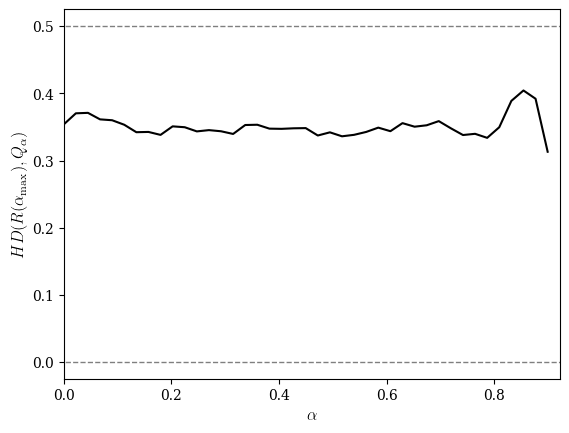

In [17]:
ax = RS.symmetry_plot(seed=SEED)
if SAVE_FIGURES: save_figure(ax.figure, "images/athens_data_symmetry_plot", fig_size=(4, 4))
plt.show()

### 7. Containment-capacity plot

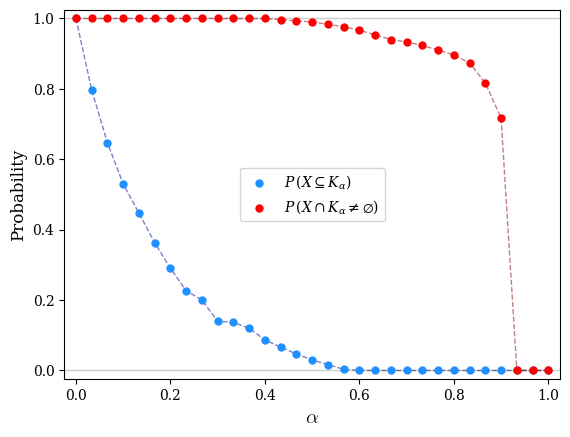

In [18]:
ax = RS.containment_capacity_plot(31)
if SAVE_FIGURES: save_figure(ax.figure, "images/athens_data_containment_capacity_plot", fig_size=(4, 4))
plt.show()